# Hands-on 26 (Bab 10): Membandingkan Baseline vs Random Forest vs LSTM Mini

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 10.

Tujuan jujur: menunjukkan kapan baseline cukup, kapan model klasik unggul, dan kapan
LSTM memberi (atau tidak memberi) nilai tambah. Dataset suhu ruang; LSTM mini
(1 layer LSTM 32 unit + Dense) dilatih dengan TensorFlow/Keras.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Random Forest pada Fitur Lag

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/forecast_room_rf.py"], capture_output=True, text=True)
print(r.stdout)

=== RANDOM FOREST ROOM FORECAST ===
MAE : 0.3350572334444412
RMSE: 0.427220835186545
[SUKSES] Hasil Random Forest suhu disimpan.



## 2. Siapkan Sequence LSTM

In [3]:
r = subprocess.run([sys.executable, "scripts/prepare_lstm_room_sequences.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Sequence LSTM disimpan di: data/processed/lstm_room
Shape X_train: (3015, 12, 1)
Train: 3015, Validation: 646, Test: 647



## 3. Latih LSTM Mini (butuh tensorflow-cpu)

In [4]:
r = subprocess.run([sys.executable, "scripts/lstm_room_forecast.py"], capture_output=True, text=True)
print(r.stdout)

=== LSTM MINI ===
MAE : 0.4894205927848816
RMSE: 0.6111241448221447
[SUKSES] Prediksi LSTM disimpan.



## 4. Perbandingan Akhir + Visualisasi

=== PERBANDINGAN MODEL FORECASTING SUHU ===
        model      mae     rmse
 RandomForest 0.335057 0.427221
MovingAverage 0.370551 0.458091
    LastValue 0.389784 0.492392
     LSTMmini 0.489421 0.611124

[SUKSES] Hasil disimpan ke: outputs/reports/room_forecast_model_comparison.csv



[SUKSES] outputs/figures/room_compare_mae.png
[SUKSES] outputs/figures/room_compare_rmse.png



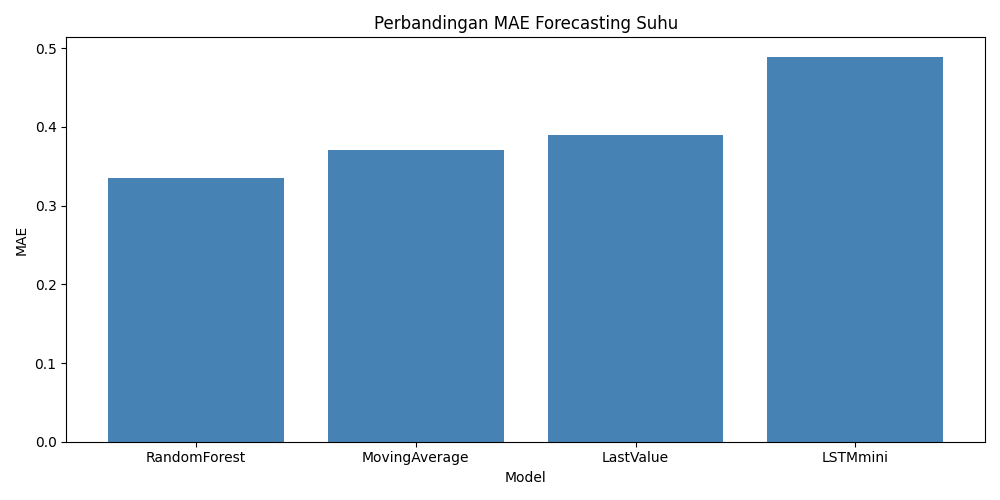

In [5]:
r = subprocess.run([sys.executable, "scripts/compare_room_forecast_models.py"], capture_output=True, text=True)
print(r.stdout)
r = subprocess.run([sys.executable, "scripts/plot_room_forecast_model_comparison.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/room_compare_mae.png")

## Penutup

Hasil: RandomForest menang (MAE 0.335 C), diikuti MovingAverage (0.371), LastValue
(0.390), dan LSTM mini justru paling buruk (0.489). Ini pelajaran penting sesuai buku:
tidak semua forecasting IoT perlu deep learning. Fitur lag/rolling pada model tabular
klasik sudah sangat kuat, dan LSTM baru layak dipertimbangkan saat data lebih banyak
dan pola temporal lebih panjang. Laporan di
`outputs/reports/room_forecast_model_comparison.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 28 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 11. Langkah kerja yang harus dilakukan pembaca

Tahap

Uraian

Siapkan dataset forecasting suhu dan energi berbasis waktu.

Bangun baseline: last value dan moving average.

Bangun model klasik: Linear Regression dan Random Forest Regressor.

Siapkan sequence untuk LSTM mini.

Latih LSTM sederhana dengan Keras.

Bandingkan semua model dengan MAE, RMSE, grafik prediksi vs aktual,
dan bar chart perbandingan metrik.

Tafsirkan hasil secara jujur: mana yang benar-benar lebih baik, mana yang
paling praktis, dan mana yang paling cocok untuk implementasi IoT.